## TP Classification :

In [3]:
import pandas as pd
dataset = pd.read_csv("new_dataset.csv")
dataset.head()

,Unnamed: 0,tweet_ID,sentiment_category,emotion_category,text,tokens,cleaned_text
0,1,1224743304690110465,negative,anger,Saw this on business insider and not on any ot...,"['Saw', 'this', 'on', 'business', 'insider', '...",saw business insider mainstream medium real do...
1,3,1224743225916825600,negative,fear,Russia has sent the first plane for evacuation...,"['Russia', 'has', 'sent', 'the', 'first', 'pla...",russia sent first plane evacuation citizen wuh...
2,8,1224743189623595014,negative,fear,Officials in Hong Kong are using wristbands to...,"['Officials', 'in', 'Hong', 'Kong', 'are', 'us...",official hong kong using wristband track famil...
3,9,1224743175199318018,negative,fear,buff.ly/2RTn8CA Camp Ashland could be coronavi...,"['buff.ly/2RTn8CA', 'Camp', 'Ashland', 'could'...",bufflyrtnca camp ashland could quarantine site...
4,12,1224743036166393856,negative,anger,The Wuhan lab knows much more about the virus ...,"['The', 'Wuhan', 'lab', 'knows', 'much', 'more...",wuhan lab know much virus theyre saying could ...


In [4]:
dataset.isnull().sum()

Unnamed: 0            0
tweet_ID              0
sentiment_category    0
emotion_category      0
text                  0
tokens                0
cleaned_text          2
dtype: int64

In [7]:
dataset.sentiment_category.value_counts()

sentiment_category
negative    2026
positive    2026
Name: count, dtype: int64

In [9]:
dataset.emotion_category.value_counts()

emotion_category
joy        2026
fear       1226
anger       637
sadness     163
Name: count, dtype: int64

## Prétraitement du Dataset :

In [12]:
#Supprimer les doublons
print("Avant :", len(dataset))
dataset = dataset.drop_duplicates(subset=["text"])
print("Après :", len(dataset))

Avant : 4052
Après : 3809


In [14]:
# Mise en minuscules
dataset["text"] = dataset["text"].str.lower()
dataset["text"].head()

0    saw this on business insider and not on any ot...
1    russia has sent the first plane for evacuation...
2    officials in hong kong are using wristbands to...
3    buff.ly/2rtn8ca camp ashland could be coronavi...
4    the wuhan lab knows much more about the virus ...
Name: text, dtype: str

In [15]:
import nltk
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
# Stemming
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem.porter import PorterStemmer
from nltk.stem.wordnet import WordNetLemmatizer

In [18]:
dataset["tokens"] = dataset["text"].apply(word_tokenize)
print("Liste des tokens :")
print(dataset["tokens"])

Liste des tokens :
0       [saw, this, on, business, insider, and, not, o...
1       [russia, has, sent, the, first, plane, for, ev...
2       [officials, in, hong, kong, are, using, wristb...
3       [buff.ly/2rtn8ca, camp, ashland, could, be, co...
4       [the, wuhan, lab, knows, much, more, about, th...
                              ...                        
4047    [``, hello, everyone, ,, this, is, li, wenlian...
4048    [#, china, national, health, commissionfeb, 4,...
4049    [i, hope, your, family, are, ok., my, best, wi...
4050    [#, japan, will, make, utmost, efforts, to, ke...
4051    [australian, wuhan, evacuees, arrive, on, chri...
Name: tokens, Length: 3809, dtype: object


In [19]:
stop_words = set(stopwords.words('english'))
print(f"Nombre de stopwords: {len(stop_words)}")
print(list(stop_words)[:20], "...")

Nombre de stopwords: 198
["doesn't", 'why', 'over', 're', 'ain', 'of', 'my', 'doing', 'hasn', "it'll", 'had', 'these', 'there', 'from', "that'll", "he's", 'have', 'here', 'how', 'after'] ...


In [20]:
def filtrer(mots):
    return [mot for mot in mots if mot not in stop_words]

tokens_filtered = dataset["tokens"].apply(filtrer)
print("Tokens après suppression des stopwords :")
print(tokens_filtered)

Tokens après suppression des stopwords :
0       [saw, business, insider, mainstream, media, !,...
1       [russia, sent, first, plane, evacuation, citiz...
2       [officials, hong, kong, using, wristbands, tra...
3       [buff.ly/2rtn8ca, camp, ashland, could, corona...
4       [wuhan, lab, knows, much, virus, ’, saying, .,...
                              ...                        
4047    [``, hello, everyone, ,, li, wenliang, ,, opht...
4048    [#, china, national, health, commissionfeb, 4,...
4049    [hope, family, ok., best, wishes, ., stand, wu...
4050    [#, japan, make, utmost, efforts, keep, novel,...
4051    [australian, wuhan, evacuees, arrive, christma...
Name: tokens, Length: 3809, dtype: object


In [21]:
import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
stop_words.update(['coronavirus',"@"])

In [22]:
def clean_text(text):
    # Minuscules
    text = text.lower()

    # Supprimer URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Supprimer caractères spéciaux et chiffres
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenisation
    tokens = word_tokenize(text)

    # Supprimer stopwords et lemmatiser
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    # Reconstituer le texte
    return ' '.join(tokens)

# Créer la nouvelle colonne
dataset['cleaned_text'] = dataset['text'].apply(clean_text)

In [23]:
dataset.head()

,Unnamed: 0,tweet_ID,sentiment_category,emotion_category,text,tokens,cleaned_text
0,1,1224743304690110465,negative,anger,saw this on business insider and not on any ot...,"[saw, this, on, business, insider, and, not, o...",saw business insider mainstream medium real do...
1,3,1224743225916825600,negative,fear,russia has sent the first plane for evacuation...,"[russia, has, sent, the, first, plane, for, ev...",russia sent first plane evacuation citizen wuh...
2,8,1224743189623595014,negative,fear,officials in hong kong are using wristbands to...,"[officials, in, hong, kong, are, using, wristb...",official hong kong using wristband track famil...
3,9,1224743175199318018,negative,fear,buff.ly/2rtn8ca camp ashland could be coronavi...,"[buff.ly/2rtn8ca, camp, ashland, could, be, co...",bufflyrtnca camp ashland could quarantine site...
4,12,1224743036166393856,negative,anger,the wuhan lab knows much more about the virus ...,"[the, wuhan, lab, knows, much, more, about, th...",wuhan lab know much virus theyre saying could ...


### Vectorisation 

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Création du vectoriseur
tfidf = TfidfVectorizer()

# Vectorisation de la colonne cleaned_text
X_tfidf = tfidf.fit_transform(dataset["cleaned_text"])

print("Shape :", X_tfidf.shape)

Shape : (3809, 11934)


In [28]:
X = X_tfidf
y = dataset["sentiment_category"]

### Séparation des données

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=70,
    stratify=y
)

### Les modèles 

In [32]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

texts = [
    "I really like this product",
    "This product is terrible",
    "The service was excellent",
    "I am very disappointed"
]

#### SVM

In [43]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [44]:
y_pred_svm = svm_model.predict(X_test)

In [45]:
accuracy = accuracy_score(y_test, y_pred_svm)

print("Accuracy :", accuracy)

print(classification_report(y_test, y_pred_svm))

Accuracy : 0.7585301837270341
              precision    recall  f1-score   support

    negative       0.77      0.76      0.76       392
    positive       0.75      0.76      0.75       370

    accuracy                           0.76       762
   macro avg       0.76      0.76      0.76       762
weighted avg       0.76      0.76      0.76       762



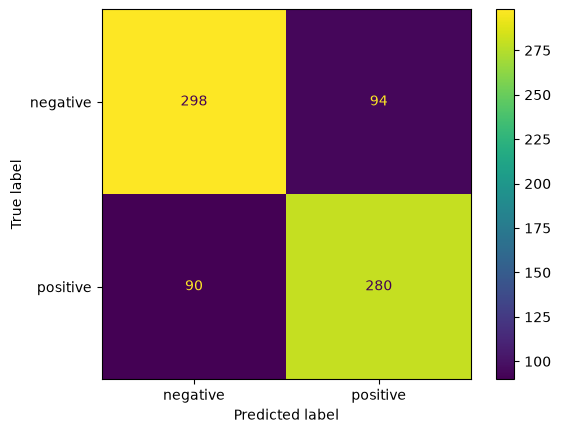

In [48]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm
)

plt.show()

In [51]:
texts_tfidf = tfidf.transform(texts)

predictions = svm_model.predict(texts_tfidf)

for text, prediction in zip(texts, predictions):
    print(f"{text} --> {prediction}")

I really like this product --> negative
This product is terrible --> positive
The service was excellent --> positive
I am very disappointed --> negative


In [52]:
from sklearn.model_selection import cross_val_score
model = LinearSVC()
scores = cross_val_score(model,X,y,cv=5,scoring="accuracy")
print(scores)

[0.77165354 0.77821522 0.80052493 0.75853018 0.73981603]


#### K-Nearest Neighbors

In [54]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5, metric="cosine")

knn_model.fit(X_train, y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['negative','positive']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'cosine'


In [55]:
y_pred_knn = knn_model.predict(X_test)

In [56]:
accuracy = accuracy_score(y_test, y_pred_knn)

print("Accuracy :", accuracy)

print(classification_report(y_test, y_pred_knn))

Accuracy : 0.6771653543307087
              precision    recall  f1-score   support

    negative       0.69      0.67      0.68       392
    positive       0.66      0.68      0.67       370

    accuracy                           0.68       762
   macro avg       0.68      0.68      0.68       762
weighted avg       0.68      0.68      0.68       762



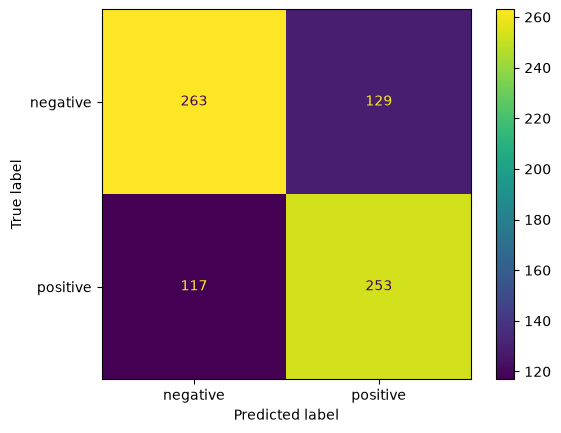

In [57]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn
)

plt.show()

In [58]:
texts_tfidf = tfidf.transform(texts)

predictions = knn_model.predict(texts_tfidf)

for text, prediction in zip(texts, predictions):
    print(f"{text} --> {prediction}")

I really like this product --> negative
This product is terrible --> positive
The service was excellent --> positive
I am very disappointed --> negative


In [59]:
from sklearn.model_selection import cross_val_score
model =  KNeighborsClassifier(n_neighbors=5, metric="cosine")
scores = cross_val_score(model,X,y,cv=5,scoring="accuracy")
print(scores)

[0.68503937 0.69685039 0.70603675 0.68635171 0.69908016]


#### Arbre de décision

In [75]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [76]:
y_pred_dt = dt_model.predict(X_test)

In [77]:
accuracy = accuracy_score(y_test, y_pred_dt)

print("Accuracy :", accuracy)

print(classification_report(y_test, y_pred_dt))

Accuracy : 0.6797900262467191
              precision    recall  f1-score   support

    negative       0.67      0.73      0.70       392
    positive       0.69      0.63      0.66       370

    accuracy                           0.68       762
   macro avg       0.68      0.68      0.68       762
weighted avg       0.68      0.68      0.68       762



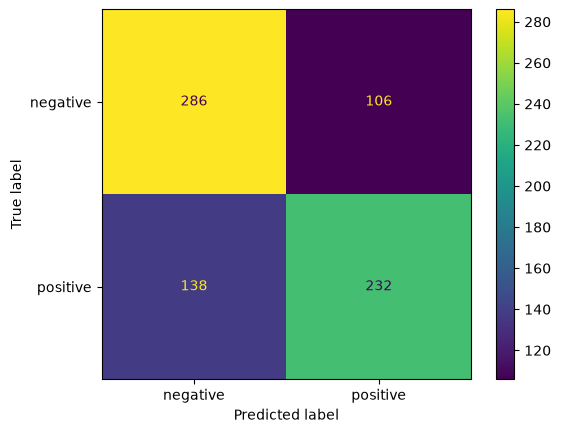

In [82]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt
)

plt.show()

In [84]:
texts_tfidf = tfidf.transform(texts)

predictions = dt_model.predict(texts_tfidf)

for text, prediction in zip(texts, predictions):
    print(f"{text} --> {prediction}")

I really like this product --> positive
This product is terrible --> negative
The service was excellent --> negative
I am very disappointed --> negative


In [85]:
from sklearn.model_selection import cross_val_score
model = DecisionTreeClassifier(random_state=42)
scores = cross_val_score(model,X,y,cv=5,scoring="accuracy")
print(scores)

[0.67454068 0.64698163 0.67454068 0.67322835 0.67148489]


### 1. Quel modèle obtient la meilleure performance globale ?

Le SVM obtient la meilleure performance globale, avec une accuracy de 0,759 sur le test.

### 2. Que remarquez-vous entre les scores de validation croisée et les résultats sur le test ?

L’arbre de décision obtient des scores entre 0,647 et 0,675 lors des 5 tests de validation croisée,ses résultats changent très peu d’un folds à l’autre.
Cela signifie que l’arbre donne des résultats assez réguliers mais qu’il n’est pas très performant par rapport au SVM qui atteint environ 0.77 


# Partie 2 : Classification multiclasse (OneVsRest)


In [2]:
import pandas as pd
dataset = pd.read_csv("new_dataset_MultiClasse.csv")
dataset.head()

,Unnamed: 0,tweet_ID,sentiment_category,emotion_category,text
0,1,1224743304690110465,negative,anger,Saw this on business insider and not on any ot...
1,3,1224743225916825600,negative,fear,Russia has sent the first plane for evacuation...
2,8,1224743189623595014,negative,fear,Officials in Hong Kong are using wristbands to...
3,9,1224743175199318018,negative,fear,buff.ly/2RTn8CA Camp Ashland could be coronavi...
4,12,1224743036166393856,negative,anger,The Wuhan lab knows much more about the virus ...


In [3]:
dataset.isnull().sum()

Unnamed: 0            0
tweet_ID              0
sentiment_category    0
emotion_category      0
text                  0
dtype: int64

In [4]:
dataset.sentiment_category.value_counts()

sentiment_category
negative    2146
positive    2146
neutral     2146
Name: count, dtype: int64

### New MultiClasseDataSet :

In [149]:
datasetPositive = dataset[dataset['sentiment_category']=='positive']
datasetPositive = datasetPositive.head(2146)

In [151]:
datasetNegative = dataset[dataset['sentiment_category']=='negative']
datasetNegative = datasetNegative.head(2146)

In [153]:
datasetNeutre = dataset[dataset['sentiment_category']=='neutral']
datasetNeutre = datasetNeutre.head(2146)

In [155]:
new_dataset = pd.concat([datasetNegative,datasetPositive,datasetNeutre])

In [157]:
new_dataset.to_csv("new_dataset_MultiClasse.csv", index=False)

In [8]:
#Supprimer les doublons
print("Avant :", len(dataset))
dataset = dataset.drop_duplicates(subset=["text"])
print("Après :", len(dataset))

Avant : 6438
Après : 5941


In [10]:
# Mise en minuscules
dataset["text"] = dataset["text"].str.lower()
dataset["text"].head()

0    saw this on business insider and not on any ot...
1    russia has sent the first plane for evacuation...
2    officials in hong kong are using wristbands to...
3    buff.ly/2rtn8ca camp ashland could be coronavi...
4    the wuhan lab knows much more about the virus ...
Name: text, dtype: str

In [12]:
import nltk
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
# Stemming
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem.porter import PorterStemmer
from nltk.stem.wordnet import WordNetLemmatizer

In [13]:
dataset["tokens"] = dataset["text"].apply(word_tokenize)
print("Liste des tokens :")
print(dataset["tokens"])

Liste des tokens :
0       [saw, this, on, business, insider, and, not, o...
1       [russia, has, sent, the, first, plane, for, ev...
2       [officials, in, hong, kong, are, using, wristb...
3       [buff.ly/2rtn8ca, camp, ashland, could, be, co...
4       [the, wuhan, lab, knows, much, more, about, th...
                              ...                        
6428    [resilience360, analyzes, supply, chain, impac...
6429    [cambodia, ’, s, hun, sen, offers, wuhan, visi...
6430    [wuhan, coronavirus, :, russia, 's, magnit, su...
6434    [skype, interview, -, international, student, ...
6437    [now, on, naijareports.comfrom, wuhan, to, wes...
Name: tokens, Length: 5941, dtype: object


In [14]:
stop_words = set(stopwords.words('english'))
print(f"Nombre de stopwords: {len(stop_words)}")
print(list(stop_words)[:20], "...")

Nombre de stopwords: 198
['them', "wasn't", 'over', 'above', "couldn't", 'few', 'hadn', "you've", 'd', 'up', 'it', "shouldn't", 'our', "he's", 'or', 'with', "i'll", 'needn', 'no', 'having'] ...


In [15]:
def filtrer(mots):
    return [mot for mot in mots if mot not in stop_words]

tokens_filtered = dataset["tokens"].apply(filtrer)
print("Tokens après suppression des stopwords :")
print(tokens_filtered)

Tokens après suppression des stopwords :
0       [saw, business, insider, mainstream, media, !,...
1       [russia, sent, first, plane, evacuation, citiz...
2       [officials, hong, kong, using, wristbands, tra...
3       [buff.ly/2rtn8ca, camp, ashland, could, corona...
4       [wuhan, lab, knows, much, virus, ’, saying, .,...
                              ...                        
6428    [resilience360, analyzes, supply, chain, impac...
6429    [cambodia, ’, hun, sen, offers, wuhan, visit, ...
6430    [wuhan, coronavirus, :, russia, 's, magnit, su...
6434    [skype, interview, -, international, student, ...
6437    [naijareports.comfrom, wuhan, west, africa, –,...
Name: tokens, Length: 5941, dtype: object


In [16]:
import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
stop_words.update(['coronavirus',"@"])

In [17]:
def clean_text(text):
    # Minuscules
    text = text.lower()

    # Supprimer URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Supprimer caractères spéciaux et chiffres
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenisation
    tokens = word_tokenize(text)

    # Supprimer stopwords et lemmatiser
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    # Reconstituer le texte
    return ' '.join(tokens)

# Créer la nouvelle colonne
dataset['cleaned_text'] = dataset['text'].apply(clean_text)

In [18]:
dataset

,Unnamed: 0,tweet_ID,sentiment_category,emotion_category,text,tokens,cleaned_text
0,1,1224743304690110465,negative,anger,saw this on business insider and not on any ot...,"[saw, this, on, business, insider, and, not, o...",saw business insider mainstream medium real do...
1,3,1224743225916825600,negative,fear,russia has sent the first plane for evacuation...,"[russia, has, sent, the, first, plane, for, ev...",russia sent first plane evacuation citizen wuh...
2,8,1224743189623595014,negative,fear,officials in hong kong are using wristbands to...,"[officials, in, hong, kong, are, using, wristb...",official hong kong using wristband track famil...
3,9,1224743175199318018,negative,fear,buff.ly/2rtn8ca camp ashland could be coronavi...,"[buff.ly/2rtn8ca, camp, ashland, could, be, co...",bufflyrtnca camp ashland could quarantine site...
4,12,1224743036166393856,negative,anger,the wuhan lab knows much more about the virus ...,"[the, wuhan, lab, knows, much, more, about, th...",wuhan lab know much virus theyre saying could ...
...,...,...,...,...,...,...,...
6428,8875,1224500578186719233,neutral,no specific emotion,resilience360 analyzes supply chain impacts of...,"[resilience360, analyzes, supply, chain, impac...",resilience analyzes supply chain impact wuhan ...
6429,8878,1224500472473518080,neutral,no specific emotion,"cambodia’s hun sen offers wuhan visit, while p...","[cambodia, ’, s, hun, sen, offers, wuhan, visi...",cambodia hun sen offer wuhan visit pakistan re...
6430,8883,1224500341548441600,neutral,no specific emotion,wuhan coronavirus: russia's magnit suspends fo...,"[wuhan, coronavirus, :, russia, 's, magnit, su...",wuhan russia magnit suspends food import china...
6434,8893,1224500140846698496,neutral,no specific emotion,skype interview - international student strand...,"[skype, interview, -, international, student, ...",skype interview international student stranded...


In [65]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(dataset["cleaned_text"])
print("Shape :", X_tfidf.shape)

y_m = dataset["sentiment_category"]

Shape : (5941, 16247)


In [67]:
X = X_tfidf
y = dataset["sentiment_category"]

In [69]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=70,
    stratify=y
)

In [71]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC

ovr_model = OneVsRestClassifier(LinearSVC())

ovr_model.fit(X_train, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LinearSVC()
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[<U8](3,)","['negative','neutral','positive']"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LinearSVC(), LinearSVC(), LinearSVC()]"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,False
n_classes_ n_classes_: intNumber of classes.,int,3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,16247
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'


In [73]:
from sklearn.model_selection import cross_val_score
model = OneVsRestClassifier(LinearSVC())
scores = cross_val_score(model,X,y,cv=5,scoring="accuracy")
print(scores)

[0.55424727 0.52356902 0.56144781 0.5479798  0.55808081]


In [86]:
y_pred = model.predict(X_test)

In [88]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

print(classification_report(y_test, y_pred))

Accuracy : 0.5651808242220353
              precision    recall  f1-score   support

    negative       0.59      0.65      0.62       415
     neutral       0.47      0.40      0.43       382
    positive       0.61      0.64      0.62       392

    accuracy                           0.57      1189
   macro avg       0.56      0.56      0.56      1189
weighted avg       0.56      0.57      0.56      1189



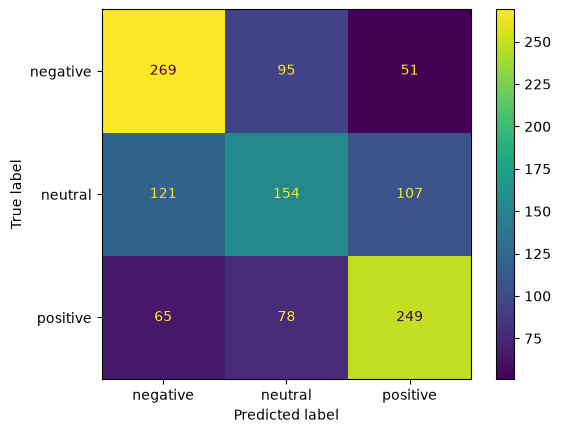

In [90]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.show()

In [98]:
from sklearn.feature_extraction.text import TfidfVectorizer
model.fit(X_train, y_train)
texts = [
    "i like this porduct very much",
    " terrible",
    "The product is okay",
    "The service was excellent",
    "I am very disappointed",
    "okey"
]

texts_tfidf = tfidf.transform(texts)

predictions = model.predict(texts_tfidf)

for text, prediction in zip(texts, predictions):
    print(f"{text} --> {prediction}")

i like this porduct very much --> negative
 terrible --> negative
The product is okay --> positive
The service was excellent --> positive
I am very disappointed --> negative
okey --> negative


### 1. Le modèle OneVsRest est-il efficace dans votre cas ?

Le modèle est moyennement efficace,avec une accuracy de 0,565 sur le test 
Il éprouve encore des difficultés à classer une phrase selon son sens global plutôt que mot à mot. Il hésite entre plusieurs prédictions et n'arrive pas à identifier correctement les phrases et les mots neutres.
### 2. Comparaison avec la classification binaire
La baisse de score : On passe de 0,759 à 0,565 (une perte de 19 points) en passant à 3 classes.

### Partie 3 : Combinaison de modèles (Majority Voting)

In [100]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

voting_model = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("nb", MultinomialNB()),
        ("svm", LinearSVC()),
    ],
    voting="hard"
)

voting_model.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('nb', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](3,)","['negative','neutral','positive']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...max_iter=1000), MultinomialNB(), LinearSVC()]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,16247


In [101]:
y_pred_vote= voting_model.predict(X_test)

In [102]:
accuracy = accuracy_score(y_test, y_pred_vote)

print("Accuracy :", accuracy)

print(classification_report(y_test, y_pred_vote))

Accuracy : 0.5592935239697224
              precision    recall  f1-score   support

    negative       0.57      0.66      0.61       415
     neutral       0.47      0.38      0.42       382
    positive       0.61      0.62      0.62       392

    accuracy                           0.56      1189
   macro avg       0.55      0.56      0.55      1189
weighted avg       0.55      0.56      0.55      1189



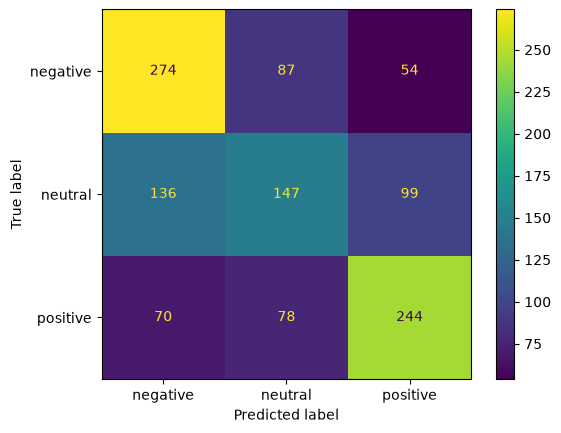

In [103]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_vote
)

plt.show()

In [108]:
texts_tfidf = tfidf.transform(texts)

predictions = voting_model.predict(texts_tfidf)

for text, prediction in zip(texts, predictions):
    print(f"{text} --> {prediction}")

i like this porduct very much --> negative
 terrible --> negative
The product is okay --> positive
The service was excellent --> positive
I am very disappointed --> negative
okey --> negative


In [112]:
from sklearn.metrics import f1_score

comparaison = pd.DataFrame({
    "Modèle": ["Logistic Regression", "Naive Bayes", "SVM", "Majority Voting"],
    "Accuracy test": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_vote),
    ],
    "F1 (pondéré)": [
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, y_pred_vote, average="weighted"),
    ],
})
comparaison.sort_values("Accuracy test", ascending=False)

,Modèle,Accuracy test,F1 (pondéré)
0,Logistic Regression,0.565181,0.560895
1,Naive Bayes,0.565181,0.560895
2,SVM,0.565181,0.560895
3,Majority Voting,0.559294,0.553727


In [116]:
preds = {"LR": y_pred, "NB": y_pred, "SVM": y_pred}

accord = pd.DataFrame(
    [[(preds[a] == preds[b]).mean() for b in preds] for a in preds],
    index=preds.keys(), columns=preds.keys()
)
accord

,LR,NB,SVM
LR,1.0,1.0,1.0
NB,1.0,1.0,1.0
SVM,1.0,1.0,1.0
